<a href="https://colab.research.google.com/github/avoutsinos/MPM_200_Antonios_Voutsinos/blob/main/Code/assignment_1_will__hummers_survive.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

<a href="https://colab.research.google.com/github/EpiPandit/MPM_200/blob/main/Session%205/Assignment%201%20-%20Will%20the%20Hummers%20Survive.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# 🐦 MPM 200 · Week 1 Assignment: *Will the Hummers Survive?*

**Due:** Wednesday 28 October 2026, 9:00 AM · **Total:** 50 points + 5 bonus

**Ground rules**
* Show your work: code **and** output. It lets us follow your thinking and give partial credit.
* Work together, but don't copy. Read each other's code until you could have written it yourself.
* Cells with blanks (`____`) won't run until you fill them in. That's on purpose.

## 📟 Mission briefing

You're the wildlife veterinarian on call for three California wildlife rehabilitation centers. Every year, hummingbirds arrive in shoeboxes and teacups: stunned by windows, carried in by cats, fallen from nests. Some go on to fly again; many don't.

The centers have pooled **more than 25 years of intake records (1991–2016)**. Your mission is to find out **which birds make it back to the sky, and what tips the odds.**

### 🗂️ Case file: data dictionary

| Column | What it records |
|---|---|
| `Admitted` | Date the bird arrived at the center |
| `Disposition_binary` | Outcome: **Died** or **Released** |
| `Place` | Rehabilitation center |
| `F_Aid` | Did the finder give first aid? (Yes/No) |
| `Species_e` | `ANHU` = Anna's Hummingbird · `BCHU` = Black-chinned Hummingbird · `Selasphorus` = orange *Selasphorus* species (e.g., Allen's, Rufous) not identified to species · `Non-selasphorus` = green birds not identified to species |
| `Sex_e`, `Age_e` | Sex and age class as recorded |
| `Brought_in_after` | Days the finder kept the bird before bringing it in |
| `season` | Season of admission |
| `r` | Reason for admission |
| `Green_Orange` | Broad group: green (non-*Selasphorus*) or orange (*Selasphorus*) |
| `ID` | Unique ID for each bird |

## 🍄 Case file 0 · Warm-up: make some noise (2 pts)

**Q0.** Install **beepr** and play the **Mario** sound. Then have a cowsay animal welcome you to the mission (use your name!).

> **Why the helper below?** `beep()` plays sound on the computer *running R*. On Colab that's a Google server with no speakers, so you'd hear nothing. The helper sends the very same sound file to **your browser** instead. On your own laptop, plain `beep("mario")` works.

In [18]:
install.packages(c("beepr", "cowsay"))
library(beepr)
library(cowsay)

# Plays a beepr sound in your browser (for Colab)
beep_colab <- function(sound = "smb_stage_clear") {     # smb_stage_clear = the Mario sound
  wav <- list.files(system.file("sounds", package = "beepr"),
                    pattern = sound, full.names = TRUE)[1]
  b64 <- jsonlite::base64_enc(readBin(wav, "raw", file.info(wav)$size))
  IRdisplay::display_html(sprintf('<audio controls autoplay src="data:audio/wav;base64,%s"></audio>', b64))
}

Installing packages into ‘/usr/local/lib/R/site-library’
(as ‘lib’ is unspecified)



In [19]:
beep_colab()     # press ▶ if your browser blocks autoplay

say("Welcome to Hummingbird HQ, Dr. Voutsinos!", by = "bird")

ERROR: [1m[33mError[39m in `say()`:[22m
[1m[22m[33m![39m `by` must be one of "alligator", "ant", "anxiouscat", "bat", "bat2",
  "beavis", "behindcat", "bigcat", "blowfish", "buffalo", "cat", "chicken",
  "chuck", "clippy", "cow_borg", "cow_dead", "cow_greedy", "cow_sleepy",
  "cow_tired", "cow_wired", "cow_young", "cow", "daemon", "dragon", "duck",
  "duckling", "egret", "endlesshorse", "facecat", "fish", "frog", "ghost",
  "goldfish", "grumpycat", "hypnotoad", "longcat", "longtailcat", "monkey",
  "mushroom", "owl", "pig", "poop", "pumpkin", "rabbit", "shark", "shortcat",
  "signbunny", "smallcat", "snowman", "spider", "squirrel", "squirrel2",
  "stegosaurus", "stretchycat", "trilobite", "turkey", "whale", "wolf", "yoda",
  "rms", or "random", not "bird".


In [20]:
library(dplyr)
library(ggplot2)
options(repr.plot.width = 7, repr.plot.height = 4.5)
dir.create("outputs", showWarnings = FALSE)

## 📋 Case file 1 · Intake: read the records

**Q1 (2 pts).** Read `Hummingbird_data.csv` into an object called `data`. It lives on the course GitHub, so you can read it straight from the URL.

In [21]:
#url <- "https://raw.githubusercontent.com/EpiPandit/MPM_200/main/data/Hummingbird_data.csv"
data <- read.csv("/Lab3_Hummingbird_data_Antonios_Voutsinos.csv")
colnames(data)


[1] "Admitted"           "Disposition_binary" "Place"             
 [4] "F_Aid"              "Species_e"          "Sex_e"             
 [7] "Age_e"              "Brought_in_after"   "season"            
[10] "r"                  "Green_Orange"       "ID"

**Q2 (1 pt).** 🔮 *Predict first:* 26 years, three centers. Guess how many birds: `6908`.
Now find how many rows and columns `data` has. 6908 rows and 12 columns

In [22]:
length(unique(data$ID))
dim(data)
nrow(data)
ncol(data)


# your code here

[1] 5000

[1] 5000   12

[1] 5000

[1] 12

**Q3 (3 pts).** Check the structure of the data.
* Use `str()` to see each column.
* Use `sapply()` with `class` to list every column's data type.
* Which columns are text (`character`) and which are numbers? Is `Admitted` stored as a date? Note anything that looks odd.

In [23]:
str(data)

data_types <- sapply(data, class)
print(data_types)

'data.frame':	5000 obs. of  12 variables:
 $ Admitted          : chr  "3/28/1998" "4/21/1998" "6/3/2015" "12/16/1992" ...
 $ Disposition_binary: chr  "Released" "Died" "Died" "Died" ...
 $ Place             : chr  "Lindsey" "Lindsey" "Lindsey" "Lindsey" ...
 $ F_Aid             : chr  "Yes" "No" "No" "No" ...
 $ Species_e         : chr  "Non-selasphorus" "ANHU" "Non-selasphorus" "ANHU" ...
 $ Sex_e             : chr  "unknown" "Female-like " "unknown" "Female-like " ...
 $ Age_e             : chr  "Nestling" "adult-like" "Nestling" "adult-like" ...
 $ Brought_in_after  : int  1 0 0 0 0 0 0 0 0 0 ...
 $ season            : chr  "Spring" "Spring" "Summer" "Winter" ...
 $ r                 : chr  "found on the ground" "caught by domestic animal" "found on the ground" "caught by domestic animal" ...
 $ Green_Orange      : chr  "Non-selasphorus spp." "Non-selasphorus spp." "Non-selasphorus spp." "Non-selasphorus spp." ...
 $ ID                : chr  "1360_ANHU" "1394_ANHU" "5356_ANHU" "368_

All the columns are "text" except from the Brought_in_after column which is "integer". Admitted column is stored as text. It is odd that even if Admitted column appears to be in a conventional date-form, it is actually "text".

### 🎲 Draw your own reproducible sample
Each of you will analyse a random sample of 5,000 birds. `set.seed()` makes "random" **repeatable**: the same seed always gives the same sample, so your instructor can reproduce your results exactly (remember the reproducibility checklist from lecture?).

👉 Replace `1225` with **your birthday as MMDD** (e.g., 3 July → `0703`, which R reads as 703).

In [25]:
set.seed(1020)                              # ← your birthday, MMDD
model_data <- slice_sample(data, n = 5000)

**Use `model_data` for the rest of the assignment.**

**Q4 (1 pt).** How many rows and columns does `model_data` have?
5000 rows and 12 columns

In [26]:
dim(model_data)
nrow(model_data)
ncol(model_data) # your code here



[1] 5000   12

[1] 5000

[1] 12

**Q5 (2 pts).** How many columns are **categorical** and how many are **continuous**? Name the continuous one(s). Is `ID` a useful variable for analysis?


✍️ **Your answer:** Continuous data: Admitted, Brought_in_after, ID (3 variables).
All the rest are categorical data (9 variables). The bird ID is pretty useful because it will help us check and remove any duplicates in this column, meaning if there are any birds registered more than one time in the data system. For our calculations and data manipulation we don't want to have duplicates in our data set, as this will affect our final results.

**Q6 (2 pts).** Save your sample as `Hummingbird_data_YOURNAME.csv` in the `outputs` folder, and submit it. Use `row.names = FALSE`.

In [27]:
write.csv(model_data, "outputs/Hummingbird_data_Antonios_Voutsinos.csv", row.names = FALSE)

## 🏥 Case file 2 · Which hospital is busiest?

Let's count how many birds each center admitted (column `Place`), using dplyr to build a summary table and ggplot2 to plot it.

In [28]:
rehab <- model_data %>%
  group_by(Place) %>%
  summarise(count = n_distinct(ID))
rehab

death_data<- data|>
  filter (Disposition_binary== "Died")|>
  group_by(Place)|>
  summarise(count_death = n_distinct(ID))
death_data



Place,count
<chr>,<int>
Lindsey,4135
Santa Barbara,67
malibu,798


Place,count_death
<chr>,<int>
Lindsey,2688
Santa Barbara,37
malibu,503


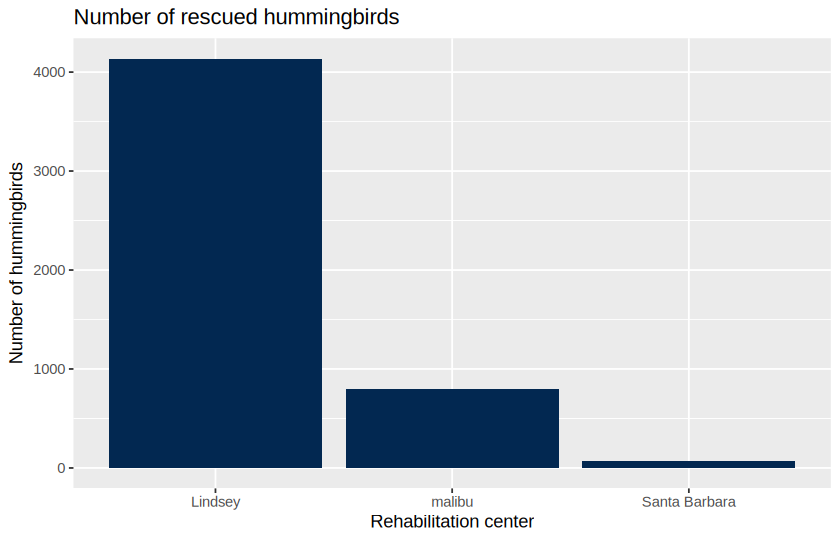

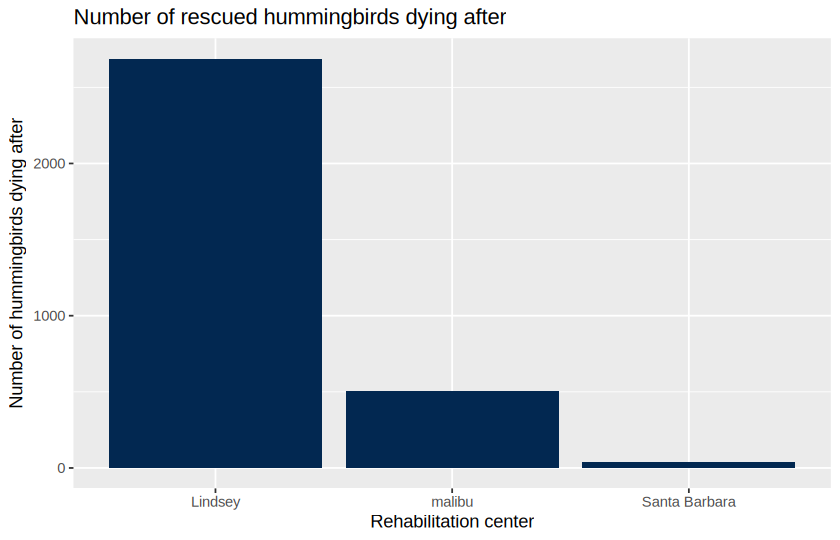

In [29]:
p <- ggplot(rehab, aes(x = Place, y = count)) +
  geom_col(fill = "#022851") +
  xlab("Rehabilitation center") +
  ylab("Number of hummingbirds") +
  labs(title = "Number of rescued hummingbirds")
p

p_death <- ggplot(death_data, aes(x = Place, y = count_death)) +
  geom_col(fill = "#022851") +
  xlab("Rehabilitation center") +
  ylab("Number of hummingbirds dying after") +
  labs(title = "Number of rescued hummingbirds dying after")
p_death

**Q7 (2 pts).** Save this plot as a **PDF, 4 inches wide and 3 inches tall**, and submit it.

In [30]:
ggsave("outputs/rehab_counts_Antonios_Voutsinos.pdf", p, width = 4, height = 3)

**Q8 (3 pts).** Explain the code in words, line by line, from the line that creates `rehab` through the plot. What does each function do?

✍️ **Your answer:** "rehab <- model_data %>%
  group_by(Place) %>%
  summarise(count = n_distinct(ID))
rehab":
We first assign the following process to rehab vector. Then, we use the pipeline (%>%) on model_data to enter the data frame.
Then we group the data frame by Place and with the "summarise" function we ask from R to count the number of unique values (n_distinct) in the bird ID column brought in the rehab centers. R will count these number seperately for each clinic because we first "grouped by" place. In the end, we ask from R to print rehab vector.

"p <- ggplot(rehab, aes(x = Place, y = count)) +
  geom_col(fill = "#022851") +
  xlab("Rehabilitation center") +
  ylab("Number of hummingbirds") +
  labs(title = "Number of rescued hummingbirds")
p":
ggplot is used to create a bar chart of rescued hummingbirds by Place and stores it in p. ggplot(rehab, aes(x = Place, y = count)) starts the plot with the rehab data frame, putting the rehab centers (Place) on the x axis and the number of birds (count) to the y axis. geom_col(fill = "#022851") draws blue bars whose heights equal the values in count. xlab() and ylab() are applied to name the respective axes, and labs(title = ) adds the plot title. Finally, typing p prints the plot.

**Q9 (2 pts).** 🤔 Lindsey admitted far more birds than the other centers. Does that mean more birds **die** at Lindsey? Why are raw counts not enough to compare outcomes between centers?

✍️ **Your answer:** This doesn't mean necessarily that more birds are going to die in Lindsay. However, looking at the count_death column of the second data frame, it becomes obvious that many more birds die in Lindsay rehab center. Raw counts are not appropriate to be compared, though. Big rehab centers admit larger amount of rescued birds (like Lindsay) and it is reasonable that they experience higher deaths in comparison to small rehab centers or centers admitting small amount of birds (like Santa Barbara). The best way to compare the deaths in each center is to calculate the proportion of birds dying by total birds admitted.

## 🔬 Case file 3 · Who survives?

**Q10 (6 pts).** Pick **three** variables you think could affect survival (e.g., `F_Aid`, `Age_e`, `r`, `season`, `Sex_e`, `Species_e`).
For **each** variable:
1. Make a table counting unique birds (`ID`) for every combination of the variable and `Disposition_binary`.
2. Plot it as bars, split into panels with `facet_grid()`.

Copy the two cells below for each variable.

In [31]:
df1 <- model_data %>%
  group_by(F_Aid, Disposition_binary) %>%
  summarise(count = n_distinct(ID), .groups = "drop")
df1

df2 <- model_data %>%
  group_by(r, Disposition_binary) %>%
  summarise(count = n_distinct(ID), .groups = "drop")
df2

df3 <- model_data %>%
  group_by(Species_e, Disposition_binary) %>%
  summarise(count = n_distinct(ID), .groups = "drop")
df3

F_Aid,Disposition_binary,count
<chr>,<chr>,<int>
No,Died,2111
No,Released,1194
Yes,Died,1117
Yes,Released,578


r,Disposition_binary,count
<chr>,<chr>,<int>
caught by domestic animal,Died,466
caught by domestic animal,Released,182
found inside,Died,114
found inside,Released,45
found on the ground,Died,1425
found on the ground,Released,715
nest-related,Died,267
nest-related,Released,410
suspect torpor-like state,Died,85


Species_e,Disposition_binary,count
<chr>,<chr>,<int>
ANHU,Died,2307
ANHU,Released,833
BCHU,Died,19
BCHU,Released,17
Non-selasphorus,Died,352
Non-selasphorus,Released,623
Selasphorus,Died,550
Selasphorus,Released,299


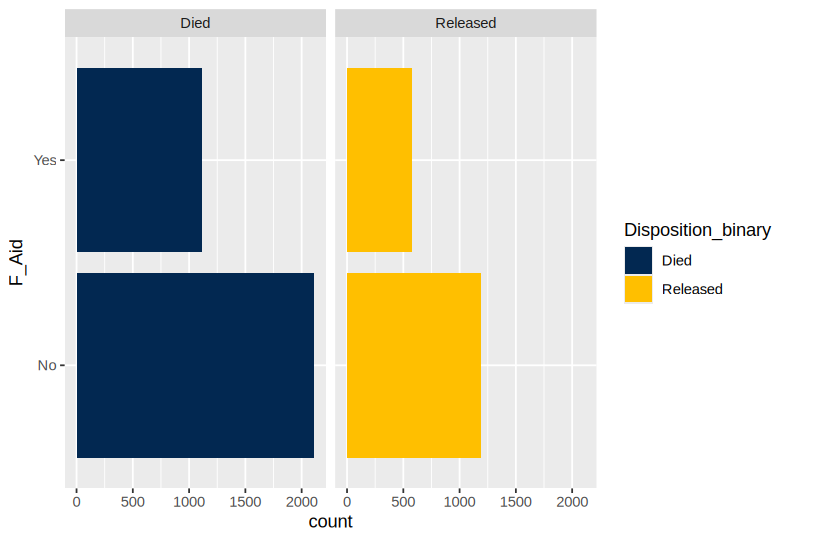

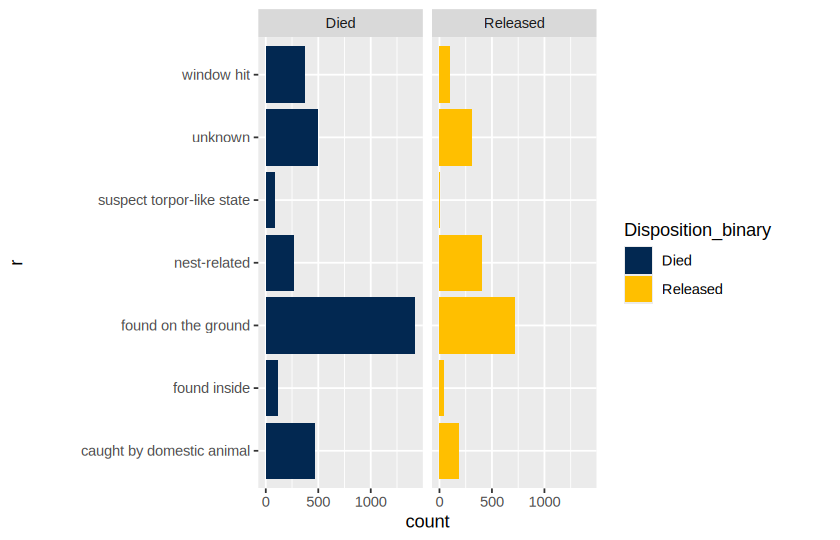

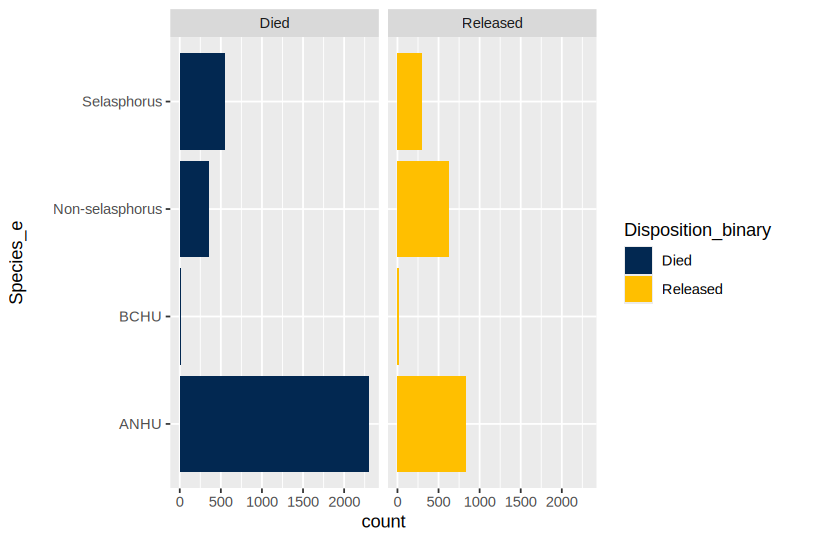

In [32]:
ggplot(df1, aes(x = F_Aid, y = count, fill = Disposition_binary)) +
  geom_col() +
  facet_grid(. ~ Disposition_binary) +
  coord_flip() +
  scale_fill_manual(values = c(Died = "#022851", Released = "#FFBF00"))

ggplot(df2, aes(x = r, y = count, fill = Disposition_binary)) +
  geom_col() +
  facet_grid(. ~ Disposition_binary) +
  coord_flip() +
  scale_fill_manual(values = c(Died = "#022851", Released = "#FFBF00"))

ggplot(df3, aes(x = Species_e, y = count, fill = Disposition_binary)) +
  geom_col() +
  facet_grid(. ~ Disposition_binary) +
  coord_flip() +
  scale_fill_manual(values = c(Died = "#022851", Released = "#FFBF00"))

**Q11 (4 pts).** What do your tables and plots suggest? Which variables look associated with the outcome? Which **statistical test** could check whether the association is more than chance?

✍️ **Your answer:** With a first look, it seems like the variables *Species* and *Reason for Admission* were associated with the outcome (Died or Released). I don't feel like First Aid played an important role for the outcome. To test the association between exposure and outcome for each exposure, I would create Rx2 tables to measure the Relative Risk Ratios, the Odds Ratios and the Attributable Risk.

### 📊 From counts to proportions
**Q12 (5 pts).** Calculate the proportion of birds **released vs. died** at each center, show the table, and plot it as side-by-side bars.

Place,Disposition_binary,count,proportion
<chr>,<chr>,<int>,<dbl>
Lindsey,Died,2688,0.6500605
Lindsey,Released,1447,0.3499395
Santa Barbara,Died,37,0.5522388
Santa Barbara,Released,30,0.4477612
malibu,Died,503,0.6303258
malibu,Released,295,0.3696742


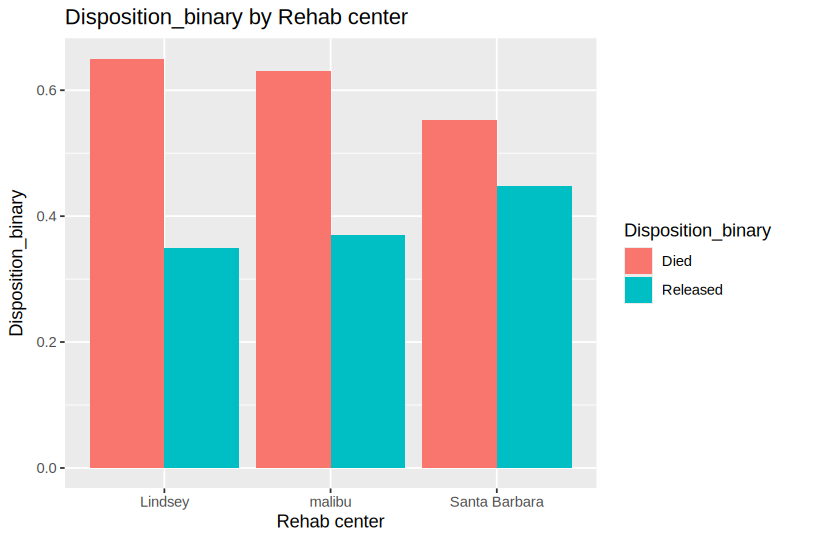

In [33]:
proportions <- model_data %>%
  group_by(Place, Disposition_binary) %>%
  summarise(count = n_distinct(ID), .groups = "drop") %>%
  group_by(Place) %>%
  mutate(proportion = count / sum(count))
proportions

ggplot(proportions, aes(x = Place, y = proportion, fill = Disposition_binary)) +
  geom_col(position = "dodge") +
  xlab("Rehab center") +
  ylab("Disposition_binary") +
  labs(title = "Disposition_binary by Rehab center")

## 🧬 Case file 4 · Green birds vs. orange birds

**Q13 (5 pts).** Make a new column `Species_group` with two groups:
* **`Selasphorus`**: all *Selasphorus* birds
* **`Non-selasphorus`**: Anna's (ANHU), Black-chinned (BCHU) and unidentified non-*Selasphorus* birds

Then tabulate and plot survival by `Species_group`. **Do survival proportions differ between the groups?**

✅ *Check yourself:* the dataset already has a `Green_Orange` column. If your grouping is right, `table(model_data$Species_group, model_data$Green_Orange)` has zeros off the diagonal.

<details><summary>💡 <b>Hint</b> (try first!)</summary>

There is only **one** value that belongs in the `Selasphorus` group, so a single `ifelse()` does it: *if* `Species_e` is `"Selasphorus"`, then `"Selasphorus"`, *else* `"Non-selasphorus"`.

</details>


                 
                  Non-selasphorus spp. Selasphorus spp.
  Non-Selasphorus                 4151                0
  Selasphorus                        0              849

`summarise()` has regrouped the output.
ℹ Summaries were computed grouped by Species_group and Disposition_binary.
ℹ Output is grouped by Species_group.
ℹ Use `summarise(.groups = "drop_last")` to silence this message.
ℹ Use `summarise(.by = c(Species_group, Disposition_binary))` for per-operation
  grouping (`?dplyr::dplyr_by`) instead.


Species_group,Disposition_binary,count,proportion
<chr>,<chr>,<int>,<dbl>
Non-Selasphorus,Died,2678,0.6451457
Non-Selasphorus,Released,1473,0.3548543
Selasphorus,Died,550,0.6478210
Selasphorus,Released,299,0.3521790


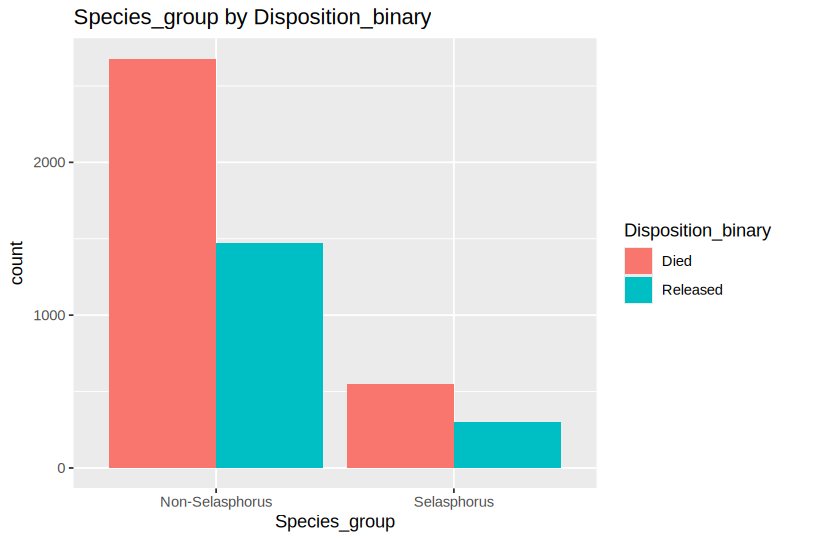

In [34]:
model_data$Species_group <- ifelse(model_data$Species_e == "Selasphorus", "Selasphorus", "Non-Selasphorus")

table(model_data$Species_group, model_data$Green_Orange)   # self-check

species_distribution <- model_data %>%
  group_by(Species_group, Disposition_binary) %>%
  summarise(count= n_distinct(ID))|>
    group_by(Species_group) %>%
  mutate(proportion = count / sum(count))
species_distribution

ggplot(species_distribution, aes(x = Species_group, y = count, fill = Disposition_binary)) +
  geom_col(position = "dodge") +
  xlab("Species_group") +
  ylab("count") +
  labs(title = "Species_group by Disposition_binary")

✍️ **Your answer:** No, the survival proportions do not differ between the two groups. As we can see in the table with the proportions, the Released and Died proportions are very close each other between the groups.

## ⏳ Case file 5 · Time traveller: admissions over the years

**Q14 (2 pts).** Convert `Admitted` to a real date. Then explain what the `format` argument does, and what would happen if you used `"%d/%m/%Y"` instead.

In [35]:
model_data$Admitted_date <- as.Date(model_data$Admitted, format = "%m/%d/%Y")
class(model_data$Admitted_date)
range(model_data$Admitted_date)

[1] "Date"

[1] "1991-01-04" "2016-12-28"

✍️ **Your answer:**

**Q15 (4 pts).** 🔮 *Predict first:* which **season** do you think brings the most hummingbirds into care? `Spring` Why? Probably because during spring dirds migrate to the northern hemisphere to track food availability and favorable weather.

Now count admissions per **month** and per **year**, and plot both timelines. Was your season prediction right? (`table(model_data$season)` will tell you.)

In [36]:
admissions_by_month <- model_data %>%
  mutate(Admitted_month = format(Admitted_date, "%Y-%m")) %>%
  group_by(Admitted_month) %>%
  summarise(count_month= n_distinct(ID))
admissions_by_month

admissions_by_year <- model_data %>%
  mutate(Admitted_year = format(Admitted_date, "%Y")) %>%
  group_by(Admitted_year) %>%
  summarise(count_year= n_distinct(ID))
admissions_by_year

table(model_data$season)

Admitted_month,count_month
<chr>,<int>
1991-01,12
1991-02,2
1991-03,23
1991-04,28
1991-05,18
1991-06,21
1991-07,13
1991-08,10
1991-09,7


Admitted_year,count_year
<chr>,<int>
1991,141
1992,130
1993,142
1994,119
1995,146
1996,141
1997,138
1998,137
1999,138



  Fall Spring Summer Winter 
   427   2275   1525    773 

In [ ]:
ggplot(admissions_by_year, aes(x = Admitted_year, y = count_year)) +
  geom_col(fill = "#022851") +
  xlab("Admitted_year") +
  ylab("count per year") +
  labs(title = "Admitted birds per year") +
  theme(axis.text.x = element_text(angle = 90, vjust = 0.5))

## now plot admissions_by_month the same way

**Q16 (2 pts).** 🕵️ **Plot twist.** Admissions roughly **triple** from 2013 onwards. Did hummingbirds suddenly get into three times more trouble? Find out what really changed.

<details><summary>💡 <b>Hint</b> (try first!)</summary>

Count admissions by year **and** `Place`: `model_data %>% count(Admitted_year = format(Admitted_date, "%Y"), Place)`. When does each center first appear?

</details>

Admitted_year,Place,n
<chr>,<chr>,<int>
1991,Lindsey,141
1992,Lindsey,130
1993,Lindsey,142
1994,Lindsey,119
1995,Lindsey,146
1996,Lindsey,141
1997,Lindsey,138
1998,Lindsey,137
1999,Lindsey,138


,Admitted,Disposition_binary,Place,F_Aid,Species_e,Sex_e,Age_e,Brought_in_after,season,r,Green_Orange,ID,Species_group,Admitted_date
,<chr>,<chr>,<chr>,<chr>,<chr>,<chr>,<chr>,<int>,<chr>,<chr>,<chr>,<chr>,<chr>,<date>
1,5/30/1991,Released,Lindsey,No,Non-selasphorus,unknown,Nestling,0,Spring,nest-related,Non-selasphorus spp.,108_ANHU,Non-Selasphorus,1991-05-30


`summarise()` has regrouped the output.
ℹ Summaries were computed grouped by Admitted_year and Species_e.
ℹ Output is grouped by Admitted_year.
ℹ Use `summarise(.groups = "drop_last")` to silence this message.
ℹ Use `summarise(.by = c(Admitted_year, Species_e))` for per-operation grouping
  (`?dplyr::dplyr_by`) instead.


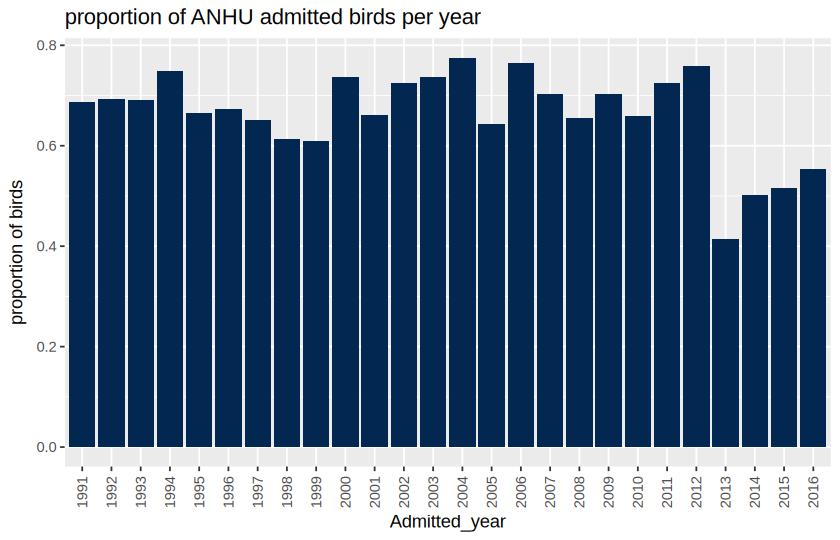

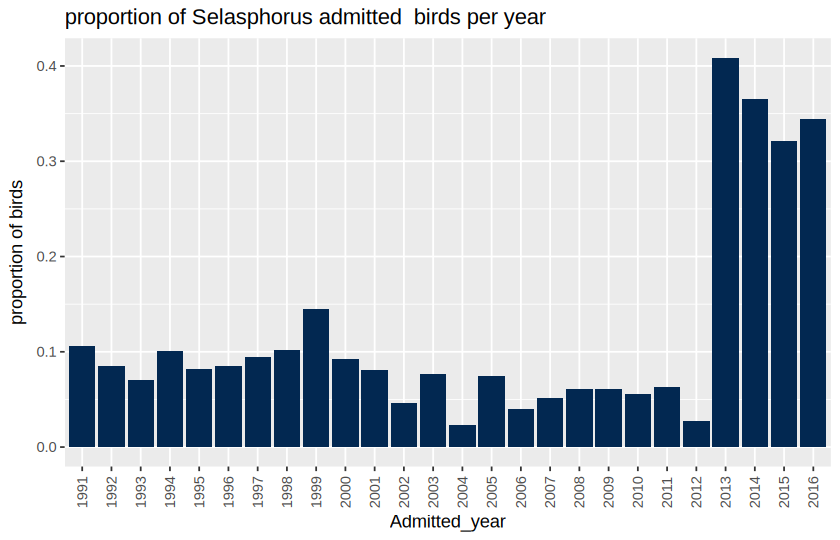

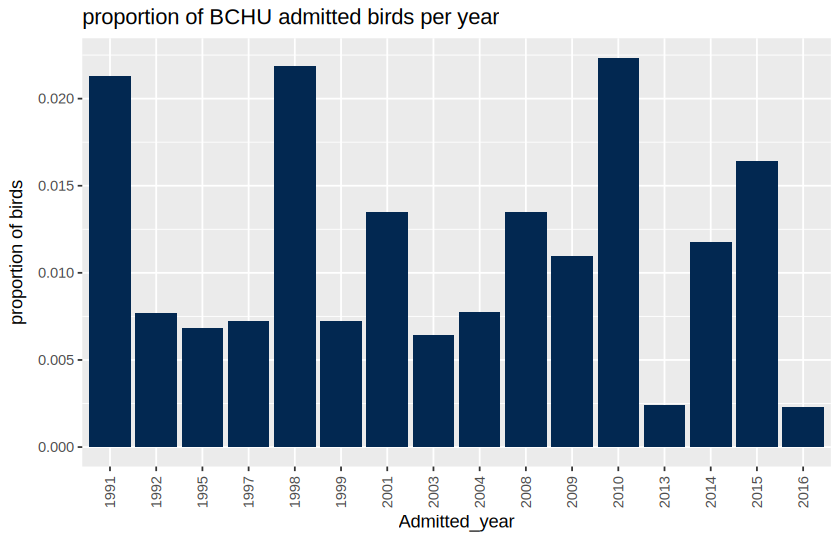

`summarise()` has regrouped the output.
ℹ Summaries were computed grouped by Admitted_year and F_Aid.
ℹ Output is grouped by Admitted_year.
ℹ Use `summarise(.groups = "drop_last")` to silence this message.
ℹ Use `summarise(.by = c(Admitted_year, F_Aid))` for per-operation grouping
  (`?dplyr::dplyr_by`) instead.


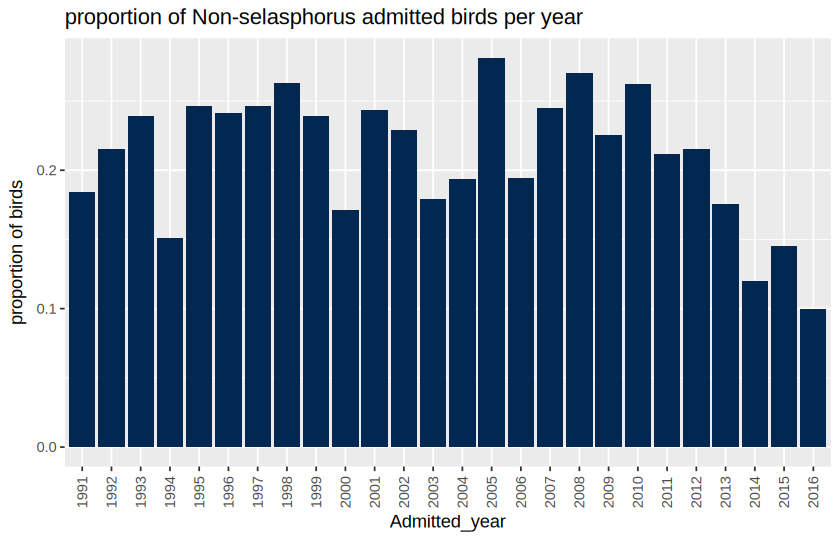

`summarise()` has regrouped the output.
ℹ Summaries were computed grouped by Admitted_year and Age_e.
ℹ Output is grouped by Admitted_year.
ℹ Use `summarise(.groups = "drop_last")` to silence this message.
ℹ Use `summarise(.by = c(Admitted_year, Age_e))` for per-operation grouping
  (`?dplyr::dplyr_by`) instead.


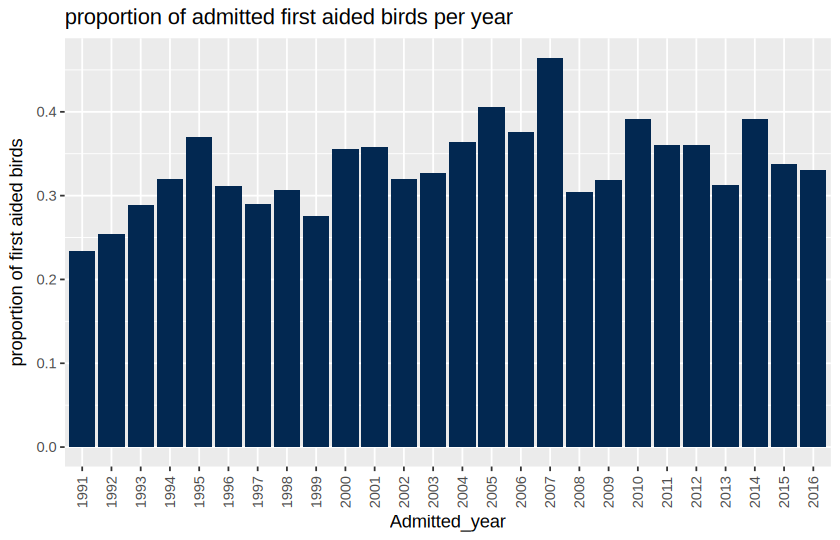

`summarise()` has regrouped the output.
ℹ Summaries were computed grouped by Admitted_year and Sex_e.
ℹ Output is grouped by Admitted_year.
ℹ Use `summarise(.groups = "drop_last")` to silence this message.
ℹ Use `summarise(.by = c(Admitted_year, Sex_e))` for per-operation grouping
  (`?dplyr::dplyr_by`) instead.


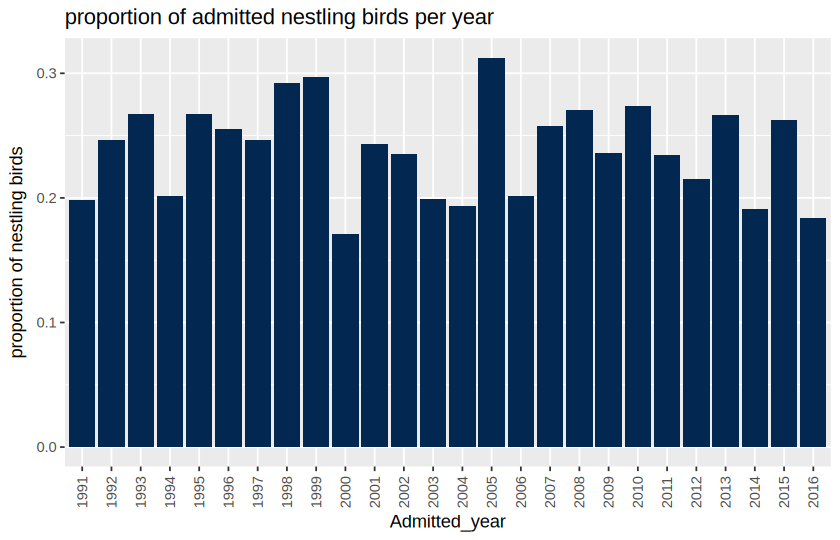

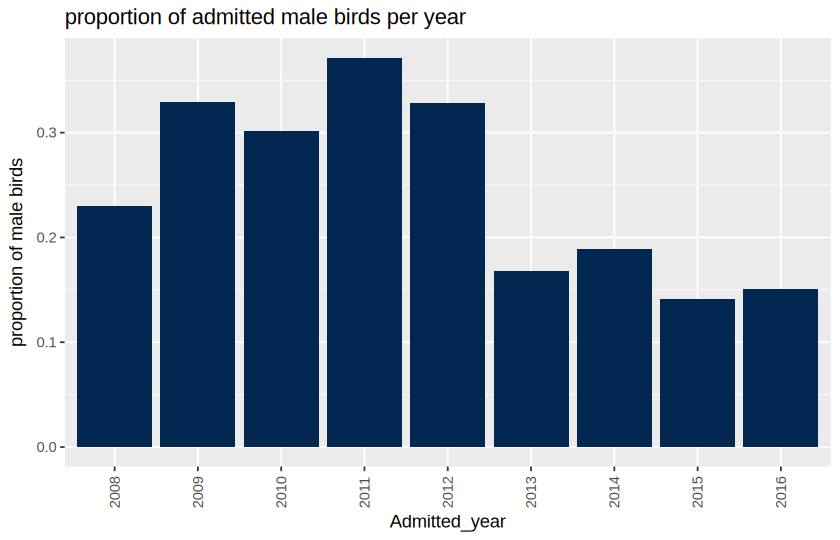

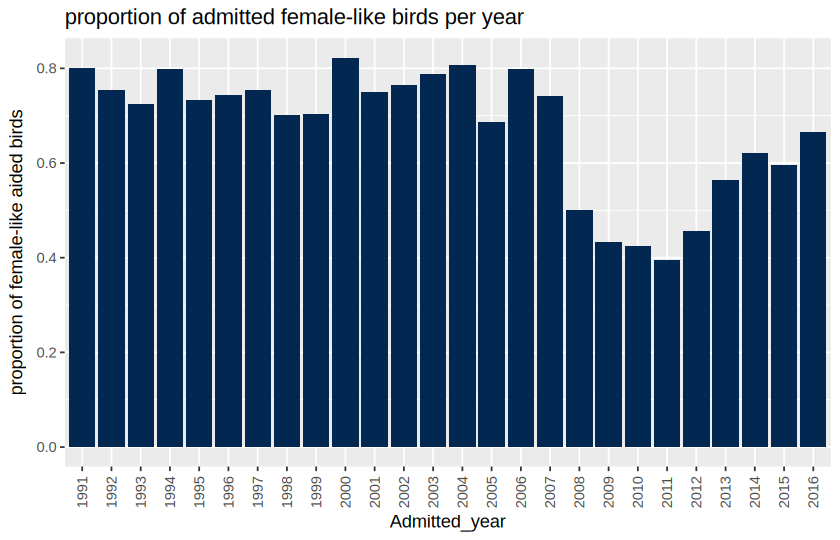

`summarise()` has regrouped the output.
ℹ Summaries were computed grouped by Admitted_year and r.
ℹ Output is grouped by Admitted_year.
ℹ Use `summarise(.groups = "drop_last")` to silence this message.
ℹ Use `summarise(.by = c(Admitted_year, r))` for per-operation grouping
  (`?dplyr::dplyr_by`) instead.


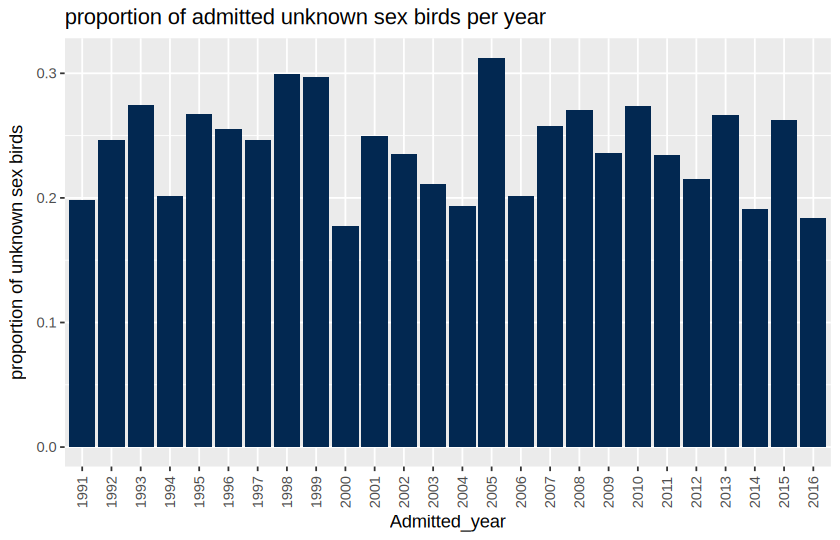

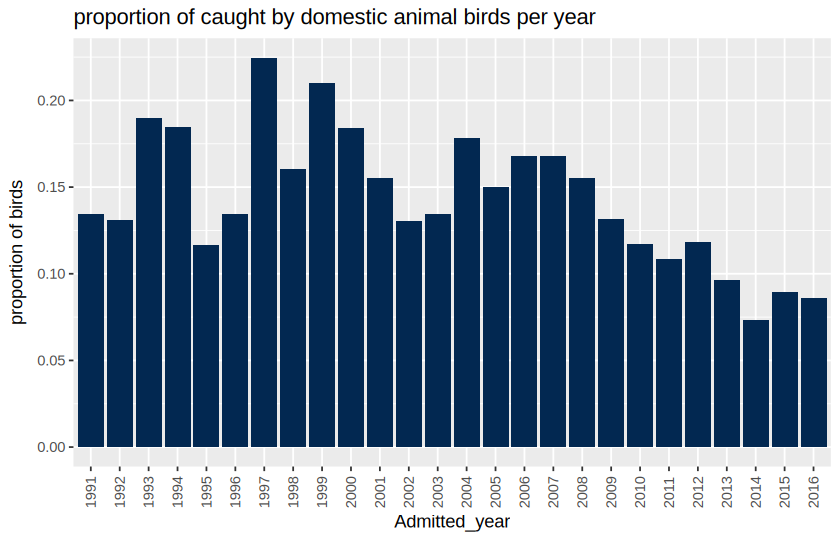

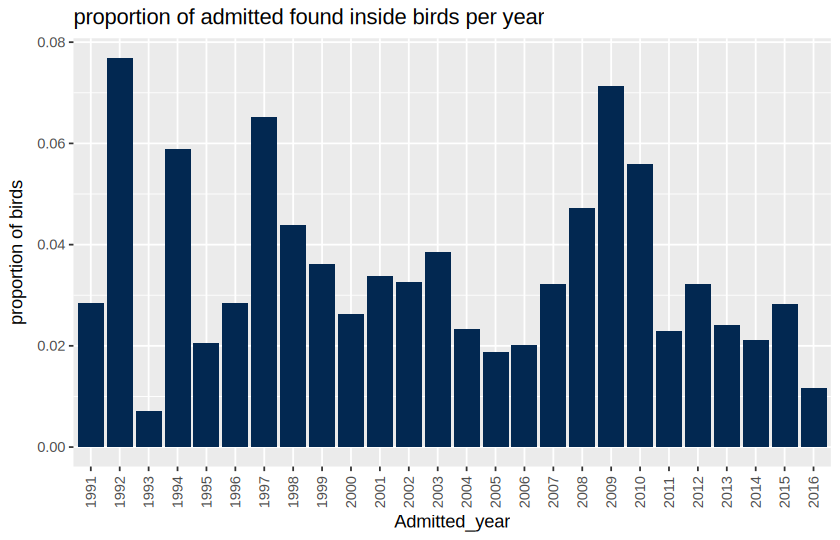

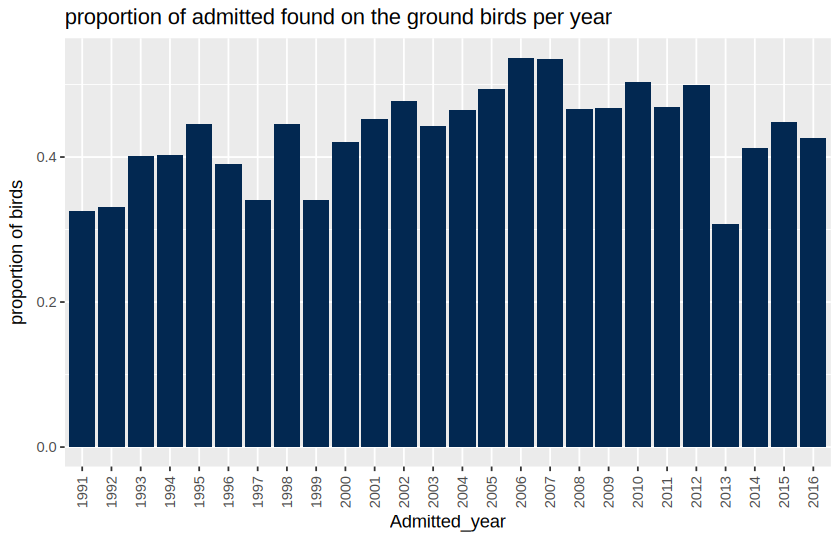

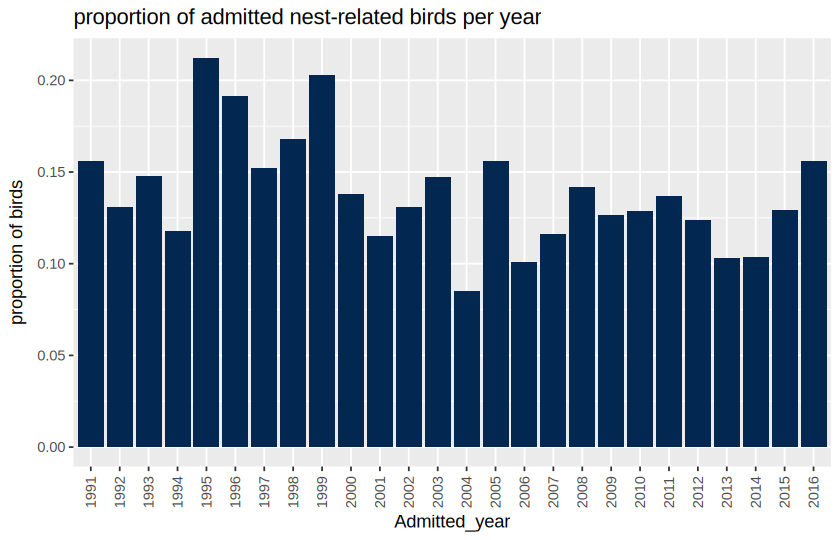

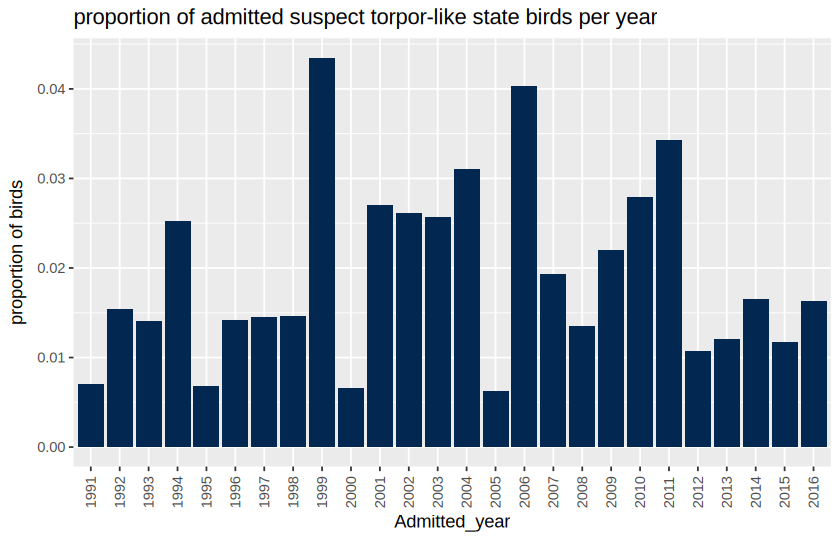

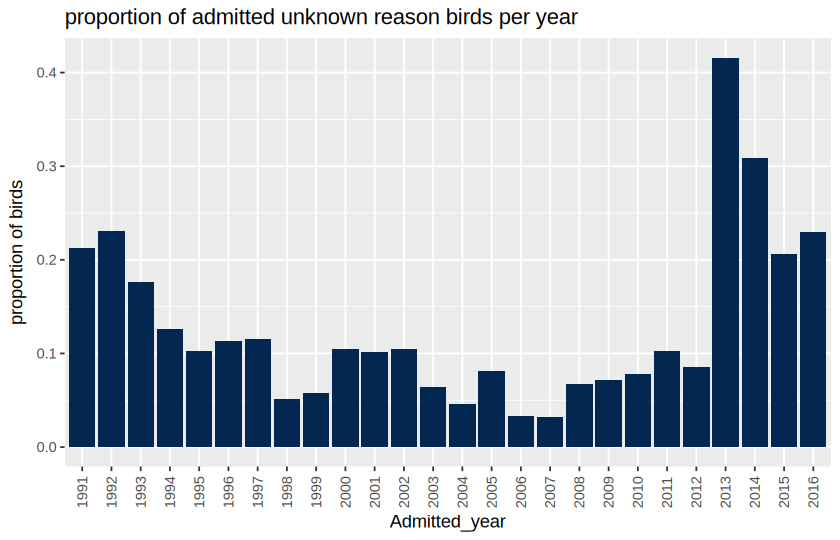

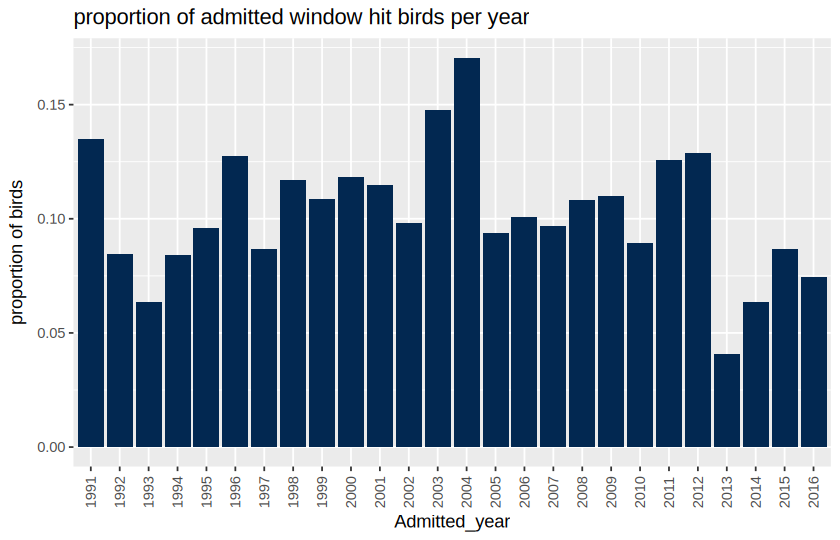

In [37]:
model_data %>% count(Admitted_year = format(Admitted_date, "%Y"), Place)
head(model_data,1)

#Species_e
model_data_year<- model_data %>%
  mutate(Admitted_year = format(Admitted_date, "%Y"))|>
    group_by(Admitted_year,Species_e)|>
    summarise(count= n_distinct(ID))|>
   group_by(Admitted_year) %>%
  mutate(proportion = count / sum(count))

ggplot(model_data_year|>filter(Species_e=="ANHU"), aes(x = Admitted_year, y = proportion)) +
  geom_col(fill = "#022851") +
  xlab("Admitted_year") +
  ylab("proportion of birds") +
  labs(title = "proportion of ANHU admitted birds per year") +
  theme(axis.text.x = element_text(angle = 90, vjust = 0.5))
ggplot(model_data_year|>filter(Species_e=="Selasphorus"), aes(x = Admitted_year, y = proportion)) +
  geom_col(fill = "#022851") +
  xlab("Admitted_year") +
  ylab("proportion of birds") +
  labs(title = "proportion of Selasphorus admitted  birds per year") +
  theme(axis.text.x = element_text(angle = 90, vjust = 0.5))
ggplot(model_data_year|>filter(Species_e=="BCHU"), aes(x = Admitted_year, y = proportion)) +
  geom_col(fill = "#022851") +
  xlab("Admitted_year") +
  ylab("proportion of birds") +
  labs(title = "proportion of BCHU admitted birds per year") +
  theme(axis.text.x = element_text(angle = 90, vjust = 0.5))
ggplot(model_data_year|>filter(Species_e=="Non-selasphorus"), aes(x = Admitted_year, y = proportion)) +
  geom_col(fill = "#022851") +
  xlab("Admitted_year") +
  ylab("proportion of birds") +
  labs(title = "proportion of Non-selasphorus admitted birds per year") +
  theme(axis.text.x = element_text(angle = 90, vjust = 0.5))


#F_Aid
model_data_year<- model_data %>%
  mutate(Admitted_year = format(Admitted_date, "%Y"))|>
    group_by(Admitted_year,F_Aid)|>
    summarise(count= n_distinct(ID))|>
   group_by(Admitted_year) %>%
  mutate(proportion = count / sum(count))


ggplot(model_data_year|>filter(F_Aid=="Yes"), aes(x = Admitted_year, y = proportion)) +
  geom_col(fill = "#022851") +
  xlab("Admitted_year") +
  ylab("proportion of first aided birds") +
  labs(title = "proportion of admitted first aided birds per year") +
  theme(axis.text.x = element_text(angle = 90, vjust = 0.5))


#Age_e
model_data_year<- model_data %>%
  mutate(Admitted_year = format(Admitted_date, "%Y"))|>
    group_by(Admitted_year,Age_e)|>
    summarise(count= n_distinct(ID))|>
   group_by(Admitted_year) %>%
  mutate(proportion = count / sum(count))

ggplot(model_data_year|>filter(Age_e=="Nestling"), aes(x = Admitted_year, y = proportion)) +
  geom_col(fill = "#022851") +
  xlab("Admitted_year") +
  ylab("proportion of nestling birds") +
  labs(title = "proportion of admitted nestling birds per year") +
  theme(axis.text.x = element_text(angle = 90, vjust = 0.5))

#Sex_e
model_data_year<- model_data %>%
  mutate(Admitted_year = format(Admitted_date, "%Y"))|>
    group_by(Admitted_year, Sex_e)|>
    summarise(count= n_distinct(ID))|>
   group_by(Admitted_year) %>%
  mutate(proportion = count / sum(count))

ggplot(model_data_year|>filter(Sex_e=="Male"), aes(x = Admitted_year, y = proportion)) +
  geom_col(fill = "#022851") +
  xlab("Admitted_year") +
  ylab("proportion of male birds") +
  labs(title = "proportion of admitted male birds per year") +
  theme(axis.text.x = element_text(angle = 90, vjust = 0.5))
ggplot(model_data_year|>filter(Sex_e=="Female-like "), aes(x = Admitted_year, y = proportion)) +
  geom_col(fill = "#022851") +
  xlab("Admitted_year") +
  ylab("proportion of female-like aided birds") +
  labs(title = "proportion of admitted female-like birds per year") +
  theme(axis.text.x = element_text(angle = 90, vjust = 0.5))
ggplot(model_data_year|>filter(Sex_e=="unknown"), aes(x = Admitted_year, y = proportion)) +
  geom_col(fill = "#022851") +
  xlab("Admitted_year") +
  ylab("proportion of unknown sex birds") +
  labs(title = "proportion of admitted unknown sex birds per year") +
  theme(axis.text.x = element_text(angle = 90, vjust = 0.5))

#r(reason)
model_data_year<- model_data %>%
  mutate(Admitted_year = format(Admitted_date, "%Y"))|>
    group_by(Admitted_year,r)|>
    summarise(count= n_distinct(ID))|>
   group_by(Admitted_year) %>%
  mutate(proportion = count / sum(count))

ggplot(model_data_year|>filter(r=="caught by domestic animal"), aes(x = Admitted_year, y = proportion)) +
  geom_col(fill = "#022851") +
  xlab("Admitted_year") +
  ylab("proportion of birds") +
  labs(title = "proportion of caught by domestic animal birds per year") +
  theme(axis.text.x = element_text(angle = 90, vjust = 0.5))
ggplot(model_data_year|>filter(r=="found inside"), aes(x = Admitted_year, y = proportion)) +
  geom_col(fill = "#022851") +
  xlab("Admitted_year") +
  ylab("proportion of birds") +
  labs(title = "proportion of admitted found inside birds per year") +
  theme(axis.text.x = element_text(angle = 90, vjust = 0.5))
ggplot(model_data_year|>filter(r=="found on the ground"), aes(x = Admitted_year, y = proportion)) +
  geom_col(fill = "#022851") +
  xlab("Admitted_year") +
  ylab("proportion of birds") +
  labs(title = "proportion of admitted found on the ground birds per year") +
  theme(axis.text.x = element_text(angle = 90, vjust = 0.5))# your detective work here
ggplot(model_data_year|>filter(r=="nest-related"), aes(x = Admitted_year, y = proportion)) +
  geom_col(fill = "#022851") +
  xlab("Admitted_year") +
  ylab("proportion of birds") +
  labs(title = "proportion of admitted nest-related birds per year") +
  theme(axis.text.x = element_text(angle = 90, vjust = 0.5))
ggplot(model_data_year|>filter(r=="suspect torpor-like state"), aes(x = Admitted_year, y = proportion)) +
  geom_col(fill = "#022851") +
  xlab("Admitted_year") +
  ylab("proportion of birds") +
  labs(title = "proportion of admitted suspect torpor-like state birds per year") +
  theme(axis.text.x = element_text(angle = 90, vjust = 0.5))
ggplot(model_data_year|>filter(r=="unknown"), aes(x = Admitted_year, y = proportion)) +
  geom_col(fill = "#022851") +
  xlab("Admitted_year") +
  ylab("proportion of birds") +
  labs(title = "proportion of admitted unknown reason birds per year") +
  theme(axis.text.x = element_text(angle = 90, vjust = 0.5))
ggplot(model_data_year|>filter(r=="window hit"), aes(x = Admitted_year, y = proportion)) +
  geom_col(fill = "#022851") +
  xlab("Admitted_year") +
  ylab("proportion of birds") +
  labs(title = "proportion of admitted window hit birds per year") +
  theme(axis.text.x = element_text(angle = 90, vjust = 0.5))



✍️ **Your answer:** Until 2012, the Lindsay rehab center was the only facility that admitted birds. The Malibu center was added in 2013, followed by the Santa Barbara center in 2016.
Observations: I observe that after 2013 more birds were brought to the rehab center for unknown reasons. In addition, more birds from Selasphorus species were brought to the centers. Finally, I realised that the rehab centers started identifying birds' male sex after 2008.

## 🕵️ Bonus · Data detective (+5 pts)

Real data are messy, and these data have **at least three problems** hiding in the *raw* file (`data`). Find three, show the code that reveals each one, and say how you would fix it **without overwriting the raw file**.

<details><summary>💡 <b>Hint</b> (try first!)</summary>

Try `summary(data$Brought_in_after)`, `unique(data$Sex_e)` (look *very* closely at the spaces), and `unique(data$Place)` (look at capitalisation).

</details>

In [38]:

summary(data$Brought_in_after)
unique(data$Sex_e)
unique(data$Place)

data2<-data|>
  mutate(Sex_e= case_when(
      Sex_e=='Female-like ' ~ 'Female-like',
      Sex_e=='Male'         ~ 'Male',
      Sex_e=='unknown'      ~ 'unknown',
      .default              = NA_character_
  ))

data3<-data2|>
  mutate(Place= case_when(
      Place=='Lindsey'              ~ 'Lindsey',
      Place=='malibu'               ~ 'Malibu',
      Place=='Santa Barbara'        ~ 'Santa Barbara',
      .default                      = NA_character_
  ))
head(data3)

data4<-data3|> mutate(Brought_in_after= ifelse(Brought_in_after<0, Brought_in_after*(-1), Brought_in_after))
data4

table(data4$Brought_in_after)

     Min.   1st Qu.    Median      Mean   3rd Qu.      Max. 
 -247.000     0.000     0.000     4.038     1.000 16588.000 

[1] "unknown"      "Female-like " "Male"

[1] "Lindsey"       "Santa Barbara" "malibu"

,Admitted,Disposition_binary,Place,F_Aid,Species_e,Sex_e,Age_e,Brought_in_after,season,r,Green_Orange,ID
,<chr>,<chr>,<chr>,<chr>,<chr>,<chr>,<chr>,<int>,<chr>,<chr>,<chr>,<chr>
1,3/28/1998,Released,Lindsey,Yes,Non-selasphorus,unknown,Nestling,1,Spring,found on the ground,Non-selasphorus spp.,1360_ANHU
2,4/21/1998,Died,Lindsey,No,ANHU,Female-like,adult-like,0,Spring,caught by domestic animal,Non-selasphorus spp.,1394_ANHU
3,6/3/2015,Died,Lindsey,No,Non-selasphorus,unknown,Nestling,0,Summer,found on the ground,Non-selasphorus spp.,5356_ANHU
4,12/16/1992,Died,Lindsey,No,ANHU,Female-like,adult-like,0,Winter,caught by domestic animal,Non-selasphorus spp.,368_ANHU
5,6/25/2016,Released,Santa Barbara,No,ANHU,Female-like,adult-like,0,Summer,nest-related,Non-selasphorus spp.,6891_ANHU
6,6/30/1994,Died,Lindsey,No,ANHU,Female-like,adult-like,0,Summer,found on the ground,Non-selasphorus spp.,689_ANHU


Admitted,Disposition_binary,Place,F_Aid,Species_e,Sex_e,Age_e,Brought_in_after,season,r,Green_Orange,ID
<chr>,<chr>,<chr>,<chr>,<chr>,<chr>,<chr>,<dbl>,<chr>,<chr>,<chr>,<chr>
3/28/1998,Released,Lindsey,Yes,Non-selasphorus,unknown,Nestling,1,Spring,found on the ground,Non-selasphorus spp.,1360_ANHU
4/21/1998,Died,Lindsey,No,ANHU,Female-like,adult-like,0,Spring,caught by domestic animal,Non-selasphorus spp.,1394_ANHU
6/3/2015,Died,Lindsey,No,Non-selasphorus,unknown,Nestling,0,Summer,found on the ground,Non-selasphorus spp.,5356_ANHU
12/16/1992,Died,Lindsey,No,ANHU,Female-like,adult-like,0,Winter,caught by domestic animal,Non-selasphorus spp.,368_ANHU
6/25/2016,Released,Santa Barbara,No,ANHU,Female-like,adult-like,0,Summer,nest-related,Non-selasphorus spp.,6891_ANHU
6/30/1994,Died,Lindsey,No,ANHU,Female-like,adult-like,0,Summer,found on the ground,Non-selasphorus spp.,689_ANHU
7/12/2001,Died,Lindsey,Yes,Selasphorus,Female-like,adult-like,0,Summer,found on the ground,Selasphorus spp.,2095_ALHU
5/17/2016,Died,Lindsey,No,Non-selasphorus,unknown,Nestling,0,Spring,nest-related,Non-selasphorus spp.,5610_ANHU
3/12/2012,Died,Lindsey,Yes,ANHU,Female-like,adult-like,0,Spring,unknown,Non-selasphorus spp.,4385_ANHU



    0     1     2     3     4     5     6     7     8     9    10    11    13 
 3717   927   137    70    33     7     7    12    10     5     7     3     3 
   14    15    16    17    18    19    20    21    22    24    25    26    27 
    2     6     1     5     3     2     2     3     3     1     2     2     2 
   30    31    37    44    48    49    68    70    81   122   159   182   241 
    4     5     1     1     1     1     1     1     1     2     1     1     1 
  244   247   262   289   367 16588 
    1     1     1     1     2     1 

✍️ **Your answer:** With the command "summary(data(*dollar_sign*)Brought_in_after)" we can see that the column includes negative values which makes no sense, as the birds were brought in AFTER they were found. So all the values should be positive in this column. To fix that, I multiplied only the negative values with (-1) in the R code.
With the command "unique(data(*dollar_sign*)Sex_e)" we can see that in the Sex_e column the female-like text includes a space in the end of the word. To fix this I converted only the 'Female-like ' text to 'Female-like'. The rest options remained the same.
 Last, With the command "unique(data(*dollar_sign*)Place)", I converted only the text 'malibu' to the capitalized word 'Malibu', with the rest options remaining the same.

## 💭 Debrief (2 pts)

**Q17.** In two or three sentences: (a) one thing in this data that surprised you, and (b) one R error you hit and how you fixed it.

✍️ **Your answer:** (a)What surprised me in this data was that some people keep the rescued birds for a long time (probably at their homes) until they bring them in the rehab centers,
(b) in the data detective bonus exercise I wrote ".default ~ NA_character" while mutating data data frame. To  fix it, I changed the ~ to =, so ".default = NA_character".

## 🎨 Hall of Fame (optional, not graded)
Make your **most beautiful** plot from this dataset, in Aggie Blue `#022851` and Aggie Gold `#FFBF00`. The best ones get shown in class. 🏆

## 📤 How to submit
1. Run every cell from the top (**Runtime → Restart and run all**) so the outputs are fresh.
2. Save the notebook to **your branch** of the course GitHub repo: File → Save a copy in GitHub (**never `main`**).
3. Download and submit `Hummingbird_data_YOURNAME.csv` and `rehab_counts_YOURNAME.pdf` from `outputs/`.

In [39]:
beep_colab("smb_stage_clear")   # mission complete 🍄

Github assignment part 5, step 7

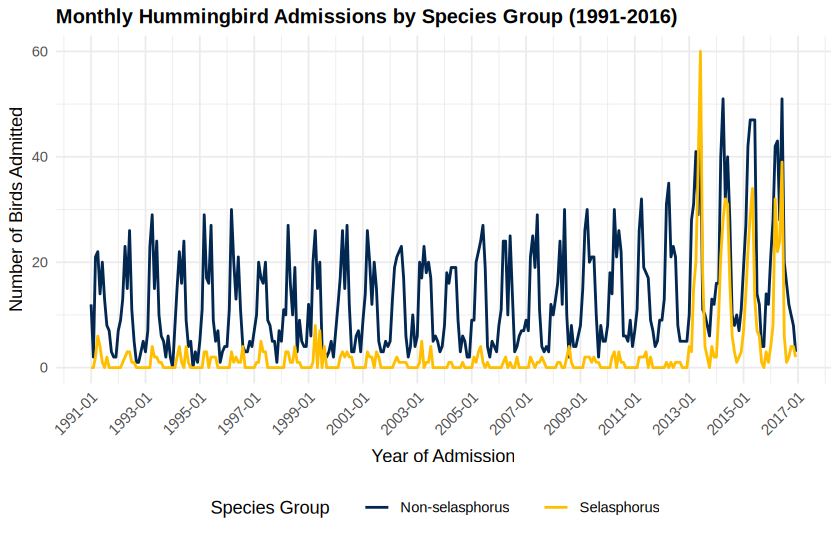

In [43]:
# Use ggplot2 to create a customized timeline plot for monthly admissions
timeline_plot <- ggplot(monthly, aes(x = month, y = n, color = Species_group)) +
  geom_line(linewidth = 0.8) +
  scale_color_manual(values = c("Non-selasphorus" = "#022851", "Selasphorus" = "#FFBF00")) +
  scale_x_date(date_breaks = "2 years", date_labels = "%Y-%m") +
  theme_minimal() +
  labs(
    title = "Monthly Hummingbird Admissions by Species Group (1991-2016)",
    x = "Year of Admission",
    y = "Number of Birds Admitted",
    color = "Species Group"
  ) +
  theme(
    legend.position = "bottom",
    plot.title = element_text(face = "bold", size = 12),
    axis.text.x = element_text(angle = 45, hjust = 1)
  )

timeline_plot